# Time Series - Large Clusters

Real station networks can easily hold dozens of series. Showing every station with its own color and label stops working well before that, so the `TimeSeriesCluster` views change their form above a number of series set by `view_specs["n_series_max"]` (10 by default).

This tutorial builds a synthetic network of 40 temperature stations to showcase these forms:

- Data availability, where the Gantt chart turns into lines
- All series in background style, and highlighting a few of them
- Correlation between many stations

```{seealso}
Check out the {doc}`Time Series - Clusters <timeseries_08_cluster>` tutorial first.
```

## Notebook setup

For users running this tutorial as a Jupyter Notebook, this cell must be executed first:

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Install `plans` in `google.colab`.
# Use `pip install plans` for other environments.

if "google.colab" in sys.modules:
    import os
    os.system(f"{sys.executable} -m pip install -q plans")

from plans.datasets import TemperatureSeries, TemperatureSeriesCluster

# This avoids warnings related to uninstalled fonts
import logging
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

rng = np.random.default_rng(seed=3)  # ensure reproducibility

## Build a large synthetic network

Forty stations are scattered over a 60 x 30 km region. The weather anomalies come from four weather centers, and each station mixes them according to its distance to each center, so nearby stations share more weather. Stations are named from west to east.

In [2]:
n_stations = 40
n = 730  # two years, daily
t = np.arange(n)

# station coordinates (km), sorted west to east
x = np.sort(rng.uniform(low=0, high=60, size=n_stations))
y = rng.uniform(low=0, high=30, size=n_stations)

def make_anomaly(phi, sd):
    # autoregressive anomaly: a[t] = phi * a[t-1] + shock
    a = np.zeros(n)
    e = rng.normal(loc=0, scale=sd, size=n)
    for i in range(1, n):
        a[i] = phi * a[i - 1] + e[i]
    return a

# weather centers and their anomalies
centers = rng.uniform(low=[0, 0], high=[60, 30], size=(4, 2))
anomalies = np.array([make_anomaly(phi=0.8, sd=1.5) for _ in centers])
cycle = 18 + 5 * np.sin(2 * np.pi * (t - 100) / 365)

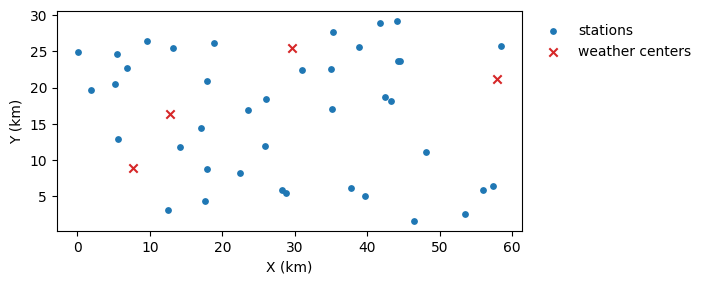

In [3]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.scatter(x, y, color="tab:blue", s=15, label="stations")
ax.scatter(centers[:, 0], centers[:, 1], color="tab:red", marker="x", label="weather centers")
ax.set_aspect("equal")
ax.set_xlabel("X (km)")
ax.set_ylabel("Y (km)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
plt.show()

## Assemble the cluster

Instead of an info table, the cluster can also be assembled in memory: set up each `TemperatureSeries` with `.set_data()` and its coordinates, then `.append()` it. Records start at random dates, and some stations have long gaps:

In [4]:
dates = pd.date_range(start="2021-01-01", periods=n, freq="D")
tsc = TemperatureSeriesCluster(name="Large Network")

for k in range(n_stations):
    # mix of weather center anomalies, closer centers weigh more
    d = np.hypot(centers[:, 0] - x[k], centers[:, 1] - y[k])
    w = np.exp(-d**2 / (2 * 15**2))
    values = cycle + (w / w.sum()) @ anomalies + rng.normal(loc=0, scale=0.8, size=n)

    # random record start and some long gaps
    values[: rng.integers(low=0, high=300)] = np.nan
    if k % 3 == 0:
        i_gap = rng.integers(low=300, high=650)
        values[i_gap : i_gap + rng.integers(low=20, high=60)] = np.nan

    name = f"ST{k + 1:02d}"
    ts = TemperatureSeries(name=name, alias=name)
    ts.set_data(
        input_df=pd.DataFrame({"datetime": dates, "T": values}),
        input_dtfield="datetime",
        input_varfield="T",
    )
    ts.x = x[k]
    ts.y = y[k]
    tsc.append(new_object=ts)

tsc.update(details=True)
print(f"Series in the cluster: {len(tsc.catalog)}")

Series in the cluster: 40


## Data availability

The Gantt chart sizes each row to the space available. With many series the bars become thin lines, and the station labels give way to a series count. The prevalence panel keeps its rows aligned with the Gantt chart, sorted by coverage:

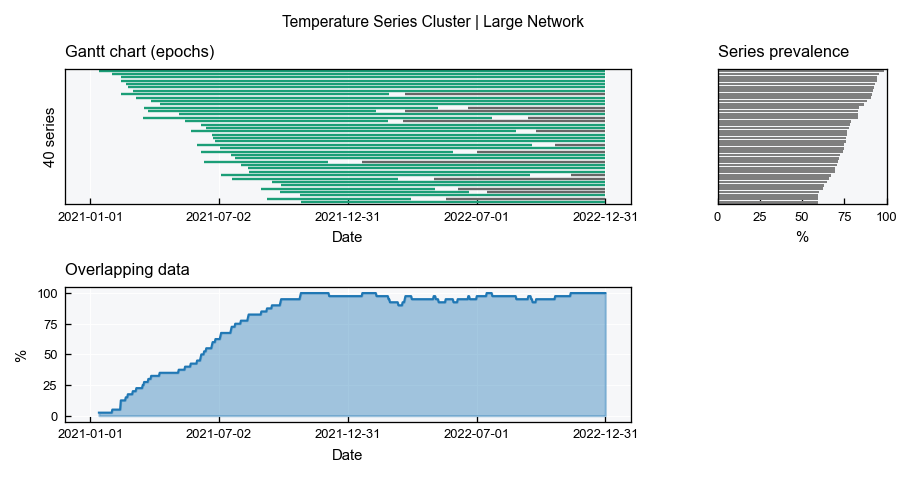

In [5]:
tsc.view()

The overlapping data panel shows how the network grows during the first year, as stations start recording, and the dips caused by the long gaps.

## All series together

Above `n_series_max`, the `series` layout draws every station in a light background style, without a legend or mean lines. The overlaid histograms add up to a shading of where values concentrate, and the CDFs show the spread among stations:

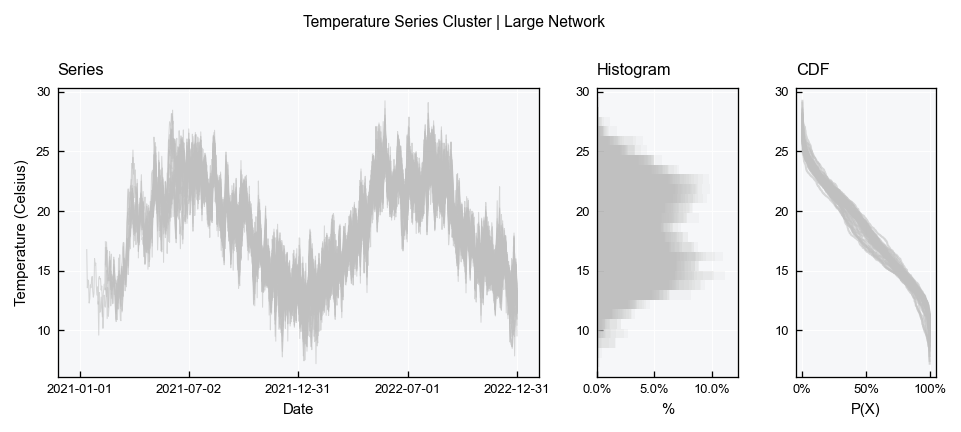

In [6]:
tsc.view_specs["layout"] = "series"
tsc.view()

### Highlighting stations

To follow particular stations, list them in `view_specs["highlight"]`. They are drawn in color, with a legend and mean lines, on top of the others. Lets highlight the westmost and the eastmost stations:

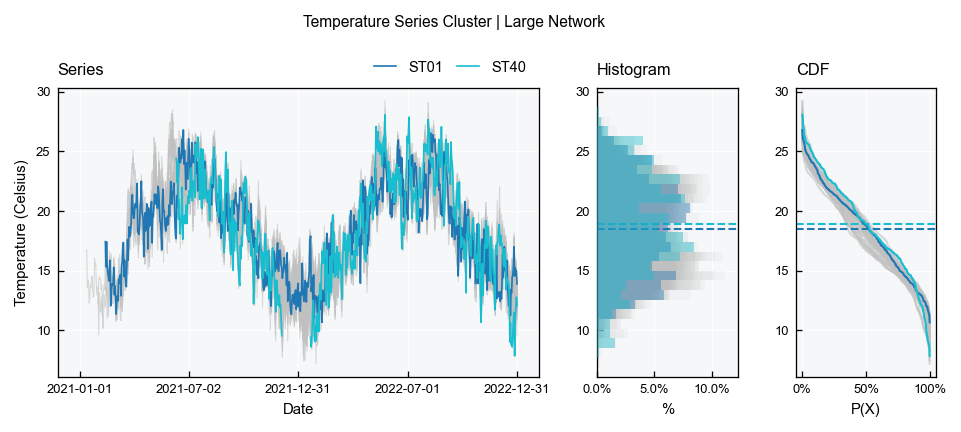

In [7]:
tsc.view_specs["highlight"] = ["ST01", "ST40"]
tsc.view()

Highlighting also works on small clusters, to point out one station among the others. To clear it, set it back to `None`.

## Correlation between many stations

The `correlation` layout also drops labels and value annotations above `n_series_max`:

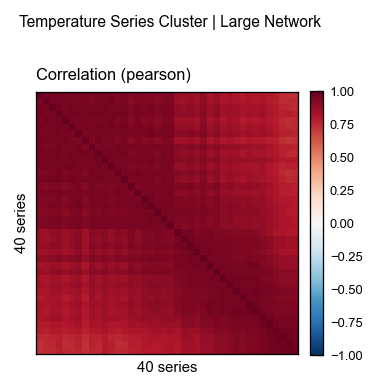

In [8]:
tsc.view_specs["highlight"] = None
tsc.view_specs["layout"] = "correlation"
tsc.view()

All stations correlate strongly, so the default color range (-1 to 1) hides the structure. Narrow it with `range_corr`. Since stations are named from west to east, the heatmap now reads as a map of how correlation changes along the region, highest near the diagonal (neighbors):

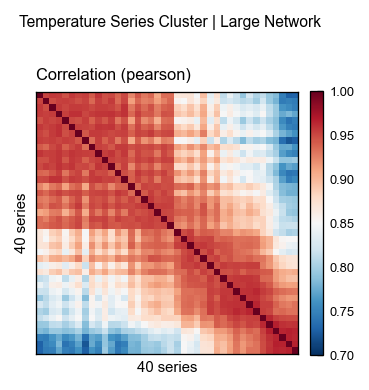

In [9]:
tsc.view_specs["range_corr"] = [0.7, 1.0]
tsc.view()

For many stations, correlation against distance is often more telling. Combine `.get_correlation()` with the station coordinates:

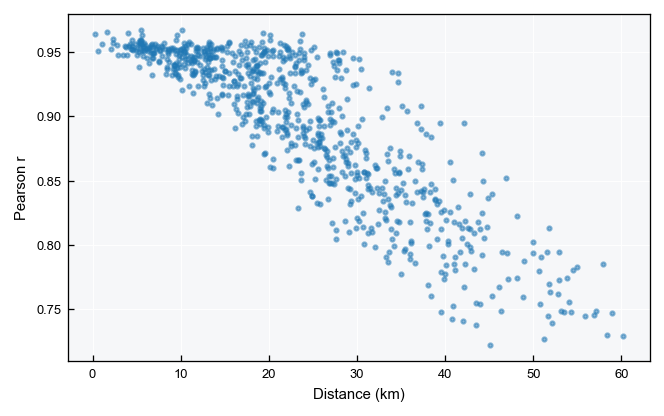

In [10]:
df_corr = tsc.get_correlation(method="pearson")
names = list(df_corr.index)
coords = {name: (tsc.collection[name].x, tsc.collection[name].y) for name in names}

ls_dist, ls_corr = [], []
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        (xi, yi), (xj, yj) = coords[names[i]], coords[names[j]]
        ls_dist.append(np.hypot(xi - xj, yi - yj))
        ls_corr.append(df_corr.iloc[i, j])

fig, ax = plt.subplots(figsize=(5, 3))
ax.scatter(ls_dist, ls_corr, s=4, color="tab:blue", alpha=0.5)
ax.set_xlabel("Distance (km)")
ax.set_ylabel("Pearson r")
plt.show()

Correlation decays with distance, as nearby stations share more weather. This is the reason why inverse distance weighting works well in `.regionalize()`.

## Recap

- Above `view_specs["n_series_max"]` series, the cluster views drop per-series labels and colors.
- The Gantt chart fits its rows to the space available, turning into lines for many series.
- `view_specs["highlight"]` draws selected stations in color over the others.
- For many stations, correlation against distance complements the heatmap.